# Titanic · 01. Исследование данных

[Соревнование](https://www.kaggle.com/competitions/titanic) · бинарная классификация · метрика: accuracy

**Задача.** По данным пассажира предсказать, выжил ли он (`Survived`). 891 пассажир с ответом (train),
418 без ответа (test).

**Что делаем в этом ноутбуке:**
1. Смотрим на данные: типы, пропуски, совпадают ли train и test.
2. Разбираем каждый признак: как он связан с выживанием и **насколько мы в этом уверены** (доверительные интервалы, тесты).
3. Ищем взаимодействия и ловушки (парадокс Симпсона, пропуски не случайно).
4. Достаём скрытые признаки из текста: титул из имени, группы по билету, палуба из каюты.
5. Записываем мысли: что пойдёт в модель и куда копать.

Признаки, которые родятся здесь, потом переедут в `kagglib.titanic.features` и будут работать в проде.

In [1]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110
pl.Config.set_tbl_rows(20)

DATA = "../../data/kaggle/titanic"
train = pl.read_csv(f"{DATA}/train.csv")
test = pl.read_csv(f"{DATA}/test.csv")
full = pl.concat([train.with_columns(pl.lit("train").alias("split")),
                  test.with_columns(pl.lit(None, pl.Int64).alias("Survived"), pl.lit("test").alias("split"))
                  .select(train.columns + ["split"])])
print(train.shape, test.shape)
train.head()

(891, 12) (418, 11)


PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
i64,i64,i64,str,str,f64,i64,i64,str,f64,str,str
1,0,3,"""Braund, Mr. Owen Harris""","""male""",22.0,1,0,"""A/5 21171""",7.25,null,"""S"""
2,1,1,"""Cumings, Mrs. John Bradley (Fl…","""female""",38.0,1,0,"""PC 17599""",71.2833,"""C85""","""C"""
3,1,3,"""Heikkinen, Miss. Laina""","""female""",26.0,0,0,"""STON/O2. 3101282""",7.925,null,"""S"""
4,1,1,"""Futrelle, Mrs. Jacques Heath (…","""female""",35.0,1,0,"""113803""",53.1,"""C123""","""S"""
5,0,3,"""Allen, Mr. William Henry""","""male""",35.0,0,0,"""373450""",8.05,null,"""S"""


### Инструмент: доля с доверительным интервалом

Почти весь анализ здесь — это «доля выживших в группе». Но в группе из 7 человек доля 0.43 и в группе из 500
доля 0.43 — разные по надёжности утверждения. Поэтому рядом с каждой долей рисуем **интервал Уилсона**.

**Матчасть.** Наивный интервал $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$ (Вальд) врёт на малых $n$ и у краёв
(при $\hat p=0$ даёт интервал нулевой ширины). Интервал Уилсона получается обращением score-теста:
ищем все $p$, для которых $|\hat p - p| \le z\sqrt{p(1-p)/n}$. Он не вылезает за $[0,1]$ и честен на малых группах.

In [2]:
def rate_table(df: pl.DataFrame, by: str | list[str], target: str = "Survived") -> pd.DataFrame:
    """Доля выживших по группам + интервал Уилсона 95%."""
    by = [by] if isinstance(by, str) else by
    t = (df.group_by(by).agg(pl.len().alias("n"), pl.col(target).sum().alias("k"))
           .sort(by).to_pandas())
    t["rate"] = t["k"] / t["n"]
    t["lo"], t["hi"] = proportion_confint(t["k"], t["n"], method="wilson")
    return t


def plot_rates(t: pd.DataFrame, x: str, ax=None, title=None, hue=None):
    """Точки = доля выживших, усы = 95% интервал Уилсона, пунктир = средняя по train."""
    ax = ax or plt.gca()
    t = t.copy()
    t["elo"] = (t["rate"] - t["lo"]).clip(lower=0)
    t["ehi"] = (t["hi"] - t["rate"]).clip(lower=0)
    cats = [str(c) for c in t[x].unique()]
    pos = {c: i for i, c in enumerate(cats)}
    groups = [(None, t)] if hue is None else list(t.groupby(hue, sort=True))
    width = 0.15 * (len(groups) - 1)
    for j, (h, s) in enumerate(groups):
        xs = np.array([pos[str(c)] for c in s[x]]) + (j * 0.15 - width / 2)
        ax.errorbar(xs, s["rate"], yerr=[s["elo"], s["ehi"]], fmt="o", capsize=4, ms=7,
                    label=None if h is None else f"{hue}={h}")
        if hue is None:
            for xi, r, n in zip(xs, s["rate"], s["n"]):
                ax.annotate(f"n={n}", (xi, r), textcoords="offset points", xytext=(8, -3), fontsize=8, color="gray")
    ax.set_xticks(range(len(cats)), cats)
    if hue is not None:
        ax.legend(fontsize=8)
    ax.axhline(train["Survived"].mean(), ls="--", c="gray", lw=1)
    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel("доля выживших")
    ax.set_title(title or x)
    return ax

## 1. Обзор: типы, пропуски, train vs test

In [3]:
pd.DataFrame({
    "dtype": [str(d) for d in train.dtypes],
    "уникальных": [train[c].n_unique() for c in train.columns],
    "пропусков train, %": [round(100 * train[c].null_count() / train.height, 1) for c in train.columns],
    "пропусков test, %": [round(100 * test[c].null_count() / test.height, 1) if c in test.columns else None
                          for c in train.columns],
}, index=train.columns)

,dtype,уникальных,"пропусков train, %","пропусков test, %"
PassengerId,Int64,891,0.0,0.0
Survived,Int64,2,0.0,NaN
Pclass,Int64,3,0.0,0.0
Name,String,891,0.0,0.0
Sex,String,2,0.0,0.0
Age,Float64,89,19.9,20.6
SibSp,Int64,7,0.0,0.0
Parch,Int64,7,0.0,0.0
Ticket,String,681,0.0,0.0
Fare,Float64,248,0.0,0.2


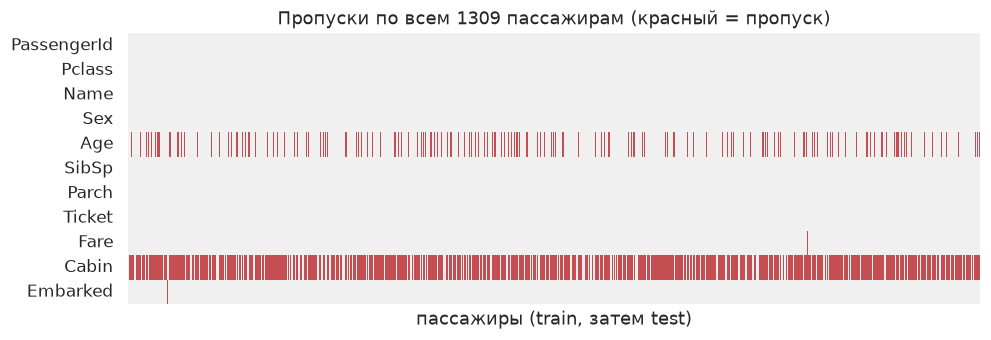

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
na = full.select(pl.all().is_null()).drop("Survived", "split").to_pandas()
sns.heatmap(na.T, cbar=False, cmap=["#f0f0f0", "#c44e52"], ax=ax, xticklabels=False)
ax.set_title("Пропуски по всем 1309 пассажирам (красный = пропуск)")
ax.set_xlabel("пассажиры (train, затем test)")
plt.show()

**Что видим:**
- `Cabin` пустой у ~77% — как признак «номер каюты» почти бесполезен, но **сам факт пропуска** может что-то значить (посмотрим).
- `Age` пустой у ~20% — много, просто выкинуть нельзя, а импутация средним сломает связь с выживанием (дети!).
- `Embarked` — 2 пропуска, `Fare` — 1 пропуск в test. Мелочи, но в проде такое должно обрабатываться, а не падать.

### Похожи ли train и test?
Если распределения отличаются, валидация на train будет обманывать. Сравним ключевые признаки.

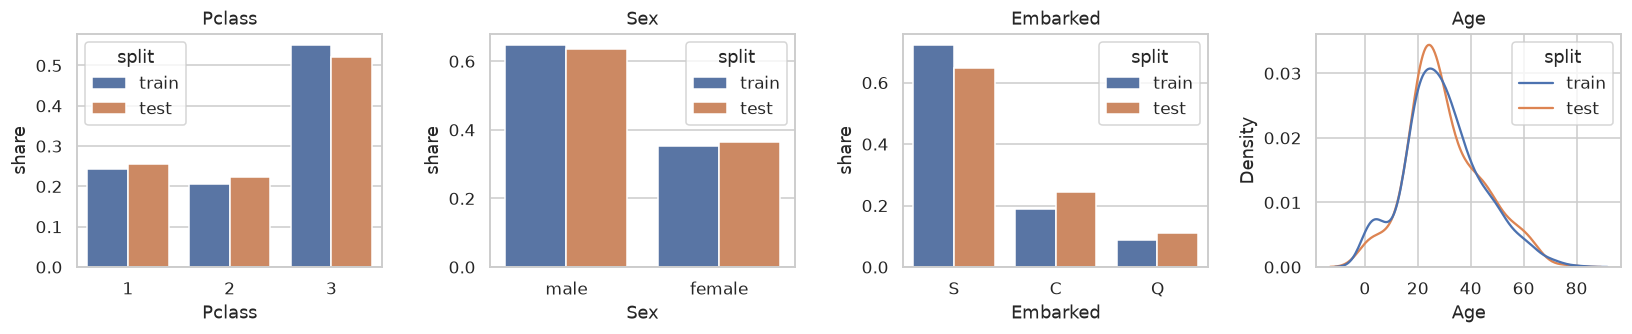

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, ["Pclass", "Sex", "Embarked"]):
    d = (full.group_by("split", col).agg(pl.len()).with_columns(
        (pl.col("len") / pl.col("len").sum().over("split")).alias("share")).to_pandas())
    sns.barplot(d, x=col, y="share", hue="split", ax=ax)
    ax.set_title(col)
sns.kdeplot(full.to_pandas(), x="Age", hue="split", common_norm=False, ax=axes[3])
axes[3].set_title("Age")
plt.tight_layout()
plt.show()

In [6]:
# Формально: тест хи-квадрат для категориальных, Колмогоров–Смирнов для числовых
rows = []
for col in ["Pclass", "Sex", "Embarked", "SibSp", "Parch"]:
    ct = full.drop_nulls(col).group_by("split", col).agg(pl.len()).pivot(on="split", index=col, values="len").fill_null(0)
    rows.append((col, "chi2", stats.chi2_contingency(ct.select("train", "test").to_numpy())[1]))
for col in ["Age", "Fare"]:
    rows.append((col, "KS", stats.ks_2samp(train[col].drop_nulls(), test[col].drop_nulls()).pvalue))
pd.DataFrame(rows, columns=["признак", "тест", "p-value"]).round(3)

,признак,тест,p-value
0,Pclass,chi2,0.602
1,Sex,chi2,0.739
2,Embarked,chi2,0.016
3,SibSp,chi2,0.511
4,Parch,chi2,0.548
5,Age,KS,0.702
6,Fare,KS,0.751


Почти все тесты говорят «распределения одинаковые». Выделяется `Embarked` (p ≈ 0.016): в test больше
пассажиров из Шербура (24% против 19%) и меньше из Southampton.

**Матчасть: множественные сравнения.** Мы сделали 7 тестов. Если различий нет вообще, шанс, что хотя бы один
даст p < 0.05 случайно, равен $1 - 0.95^7 \approx 30\%$. Поправка Бонферрони требует $p < 0.05/7 \approx 0.007$ —
по ней `Embarked` уже не значим. Вывод: сдвиг небольшой и, скорее всего, случайный, но запомним его —
в Шербуре выживали чаще (увидим ниже), так что доля выживших в test может быть чуть выше, чем в train.

В целом train и test похожи на случайное разбиение одной выборки, значит, **кросс-валидация на train — честная
оценка для test**. В реальных задачах (временные ряды, новые клиенты) так бывает редко.

## 2. Таргет

Выжило 38.4% пассажиров train. Отсюда первый «бейзлайн»: предсказать всем «погиб» → accuracy 0.616.
Любая модель, которая не обгоняет это число, ничему не научилась.

In [7]:
k, n = int(train["Survived"].sum()), train.height
lo, hi = proportion_confint(k, n, method="wilson")
print(f"выжило {k}/{n} = {k/n:.3f}, 95% ДИ [{lo:.3f}, {hi:.3f}]")
print(f"бейзлайн 'все погибли': accuracy = {1 - k/n:.3f}")

выжило 342/891 = 0.384, 95% ДИ [0.352, 0.416]
бейзлайн 'все погибли': accuracy = 0.616


## 3. Пол и класс: два главных фактора

Правило эвакуации 1912 года — «женщины и дети первыми», а шлюпки были ближе к палубам первого класса.
Проверим, насколько это видно в данных.

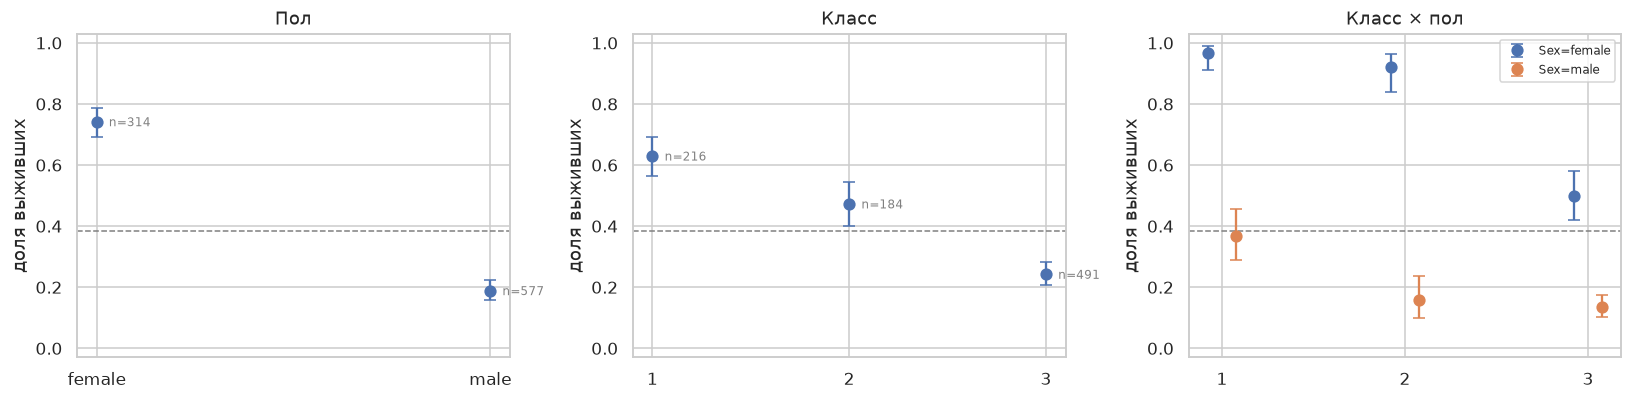

,Sex,Pclass,n,k,rate,lo,hi
0,female,1,94,91,0.968,0.910,0.989
1,female,2,76,70,0.921,0.838,0.963
2,female,3,144,72,0.500,0.419,0.581
3,male,1,122,45,0.369,0.288,0.457
4,male,2,108,17,0.157,0.101,0.238
5,male,3,347,47,0.135,0.103,0.175


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_rates(rate_table(train, "Sex"), "Sex", axes[0], "Пол")
plot_rates(rate_table(train, "Pclass"), "Pclass", axes[1], "Класс")
plot_rates(rate_table(train, ["Pclass", "Sex"]), "Pclass", axes[2], "Класс × пол", hue="Sex")
plt.tight_layout()
plt.show()
rate_table(train, ["Sex", "Pclass"]).round(3)

**Сила связи.** p-value говорит только «связь есть», но не «насколько сильная». Для силы между категориальными
используем **V Крамера**: $V = \sqrt{\chi^2 / (n \cdot (\min(r,c)-1))}$, от 0 (нет связи) до 1 (признак однозначно
определяет таргет).

In [9]:
def cramers_v(x: pl.Series, y: pl.Series) -> tuple[float, float]:
    ct = pd.crosstab(x.to_pandas(), y.to_pandas())
    chi2, p, *_ = stats.chi2_contingency(ct, correction=False)
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))), float(p)

pd.DataFrame([(c, *cramers_v(train[c].fill_null("NA") if train[c].dtype == pl.String else train[c], train["Survived"]))
              for c in ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]],
             columns=["признак", "V Крамера", "p-value"]).sort_values("V Крамера", ascending=False).round(4)

,признак,V Крамера,p-value
0,Sex,0.5434,0.0000
1,Pclass,0.3398,0.0000
3,SibSp,0.2045,0.0000
2,Embarked,0.1825,0.0000
4,Parch,0.1770,0.0001


**Что видим:**
- Пол — самый сильный признак (V ≈ 0.54). Правило «женщины выжили, мужчины нет» уже даёт accuracy 0.787.
- Женщины 1-2 класса выживают почти все (97% и 92%), мужчины 2-3 класса — почти никто (16% и 14%).
  **Модели тут почти нечего делать** — эти группы и так угадываются.
- **Женщины 3-го класса — ровно 50/50** (144 человека). И мужчины 1-го класса — 37%.
  Вся борьба за точность выше 0.79 идёт внутри этих двух групп. Запомним это — к ним вернёмся в анализе ошибок.

## 4. Порт посадки и парадокс Симпсона

На первый взгляд, порт Cherbourg (C) — «счастливый»: там выжило 55%, а в Southampton (S) — 34%.
Неужели место посадки влияет на спасение?

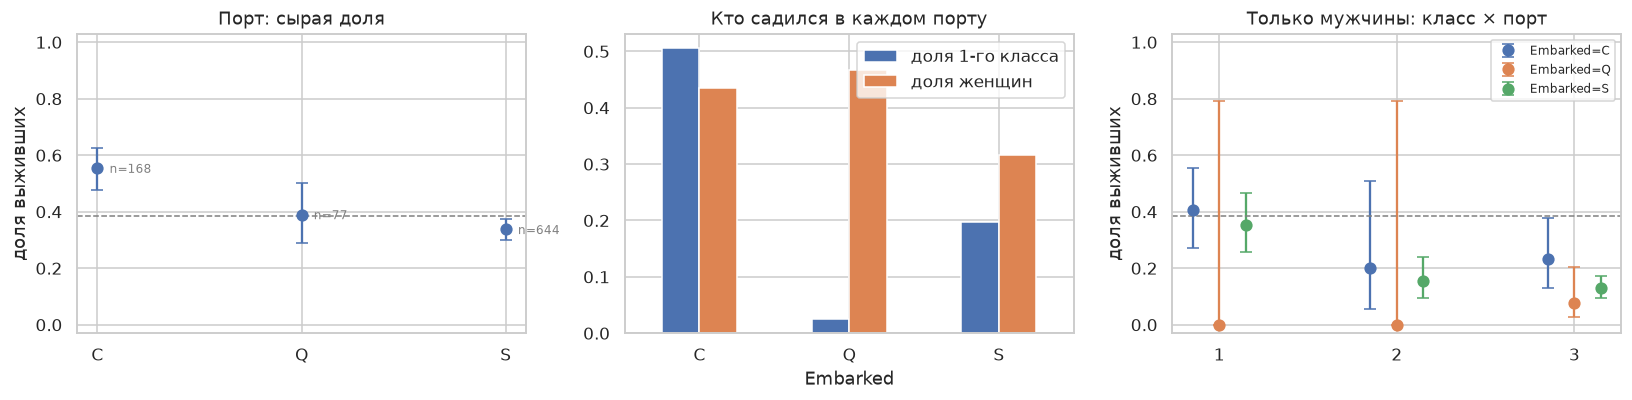

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
plot_rates(rate_table(train.drop_nulls("Embarked"), "Embarked"), "Embarked", axes[0], "Порт: сырая доля")
comp = (train.drop_nulls("Embarked").group_by("Embarked")
        .agg((pl.col("Pclass") == 1).mean().alias("доля 1-го класса"),
             (pl.col("Sex") == "female").mean().alias("доля женщин")).sort("Embarked").to_pandas())
comp.set_index("Embarked").plot.bar(ax=axes[1], rot=0, title="Кто садился в каждом порту")
plot_rates(rate_table(train.drop_nulls("Embarked").filter(pl.col("Sex") == "male"), ["Pclass", "Embarked"]),
           "Pclass", axes[2], "Только мужчины: класс × порт", hue="Embarked")
plt.tight_layout()
plt.show()

**Разгадка.** В Шербуре половина пассажиров — 1-й класс (в Квинстауне — 3%), и женщин там больше.
Порт «хороший» не сам по себе, а потому что в нём **садились те, кто и так выживал**. Это классический
**конфаундинг** (смешение): класс влияет и на порт, и на выживание.

Когда фиксируем класс и пол, разница между портами почти пропадает: женщины 1-го класса выживают на 96–98%
в любом порту. Небольшой остаток есть (мужчины 3-го класса: C — 23%, S — 13%), но интервалы на таких группах широкие.

**Для модели:** порт добавит немного сигнала поверх класса и пола, но меньше, чем кажется по сырому графику.
**Мысль на будущее:** простая таблица «группа → доля» почти всегда обманывает, если группы различаются по составу.
Это верно и для A/B-тестов, и для бизнес-отчётов.

## 5. Возраст: дети, пропуски и не случайные пропуски

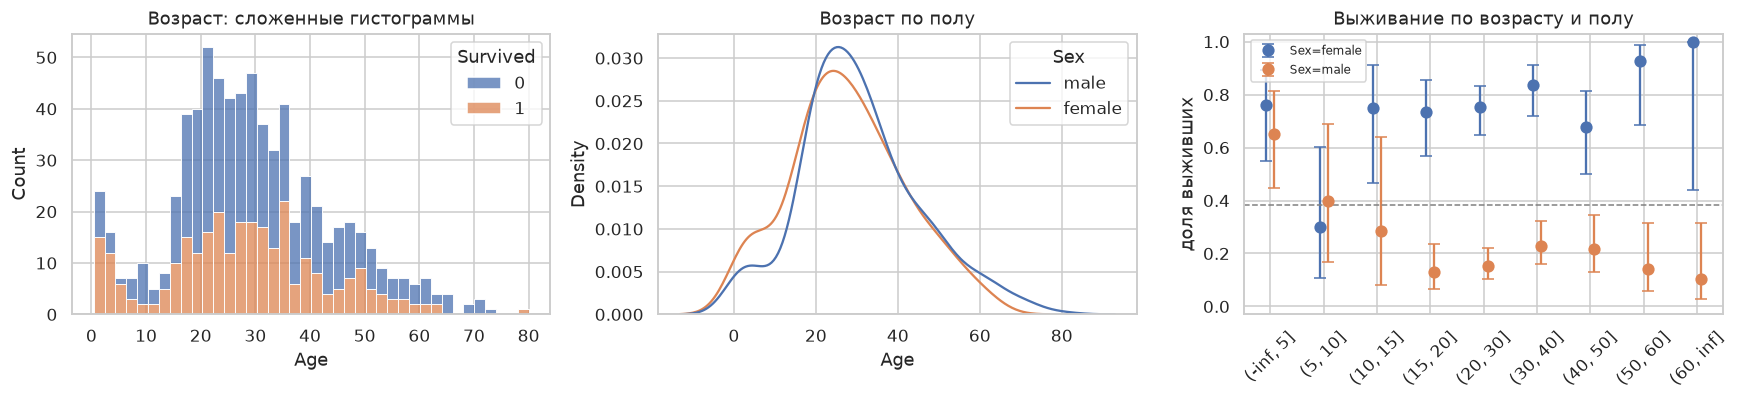

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.histplot(train.to_pandas(), x="Age", hue="Survived", bins=40, multiple="stack", ax=axes[0])
axes[0].set_title("Возраст: сложенные гистограммы")
sns.kdeplot(train.to_pandas(), x="Age", hue="Sex", ax=axes[1], common_norm=False)
axes[1].set_title("Возраст по полу")
ab = train.drop_nulls("Age").with_columns(pl.col("Age").cut([5, 10, 15, 20, 30, 40, 50, 60]).alias("AgeBin"))
plot_rates(rate_table(ab, ["AgeBin", "Sex"]), "AgeBin", axes[2], "Выживание по возрасту и полу", hue="Sex")
axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**Что видим:**
- Сам по себе возраст слабый (у взрослых гистограммы почти одинаковы), но **у детей до ~10-15 лет выживание резко выше**,
  особенно у мальчиков: мужчины выживают на 17%, мальчики до 10 — больше половины. «Женщины и дети» в данных видны.
- У стариков 60+ шансы ниже.

### Пропуски возраста — случайны?
Если пропуски случайны (MCAR), их можно спокойно заполнять. Если нет — сам факт пропуска несёт информацию.

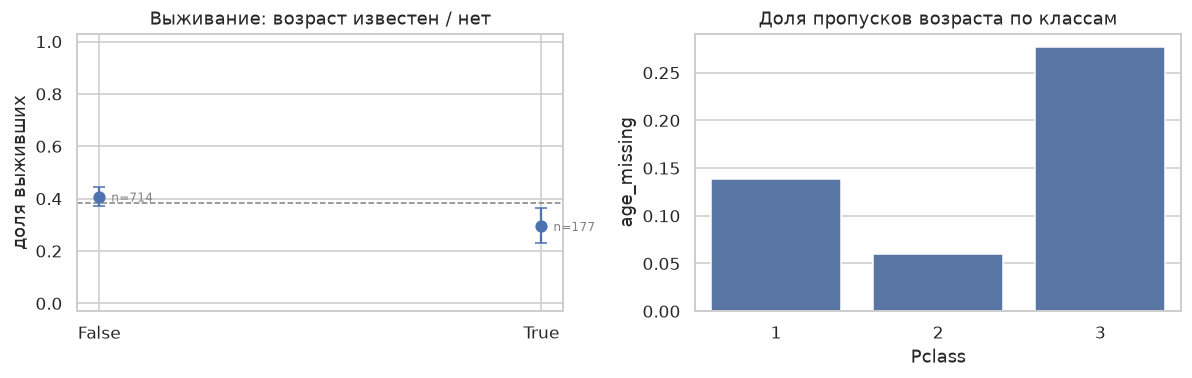

chi2 p-value (пропуск возраста vs выживание): 0.0059


In [12]:
miss = train.with_columns(pl.col("Age").is_null().alias("age_missing"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
plot_rates(rate_table(miss, "age_missing"), "age_missing", axes[0], "Выживание: возраст известен / нет")
d = miss.group_by("Pclass").agg(pl.col("age_missing").mean()).sort("Pclass").to_pandas()
sns.barplot(d, x="Pclass", y="age_missing", ax=axes[1])
axes[1].set_title("Доля пропусков возраста по классам")
plt.tight_layout()
plt.show()
print("chi2 p-value (пропуск возраста vs выживание):", round(cramers_v(miss["age_missing"], miss["Survived"])[1], 4))

Пропуски **не случайны**: у пассажиров без возраста выживание 29% против 41%, и их непропорционально много
в 3-м классе (данные о бедных пассажирах хуже сохранились). Это MAR/MNAR, а не MCAR.

**Для модели:** заполнять возраст одной медианой — плохо. Лучше (а) заполнять по группе (титул, класс) и
(б) добавить флаг `age_missing`. Деревья с флагом сами разберутся.

## 6. Титул из имени: скрытый признак

Имя выглядит бесполезным (почти у всех уникальное), но в нём сидит **титул**: `Braund, Mr. Owen Harris`.
Титул одновременно кодирует пол, примерный возраст и социальный статус.

In [13]:
TITLE_MAP = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Rare", "the Countess": "Rare", "Dona": "Rare",
             "Capt": "Rare", "Col": "Rare", "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
             "Sir": "Rare", "Jonkheer": "Rare"}
full = full.with_columns(pl.col("Name").str.extract(r",\s*([^\.]+)\.").alias("TitleRaw"))
full = full.with_columns(pl.col("TitleRaw").replace(TITLE_MAP).alias("Title"))
train_f = full.filter(pl.col("split") == "train")

print(full.group_by("TitleRaw", "split").agg(pl.len()).pivot(on="split", index="TitleRaw", values="len")
      .fill_null(0).sort("train", descending=True))

shape: (18, 3)
┌──────────────┬───────┬──────┐
│ TitleRaw     ┆ train ┆ test │
│ ---          ┆ ---   ┆ ---  │
│ str          ┆ u32   ┆ u32  │
╞══════════════╪═══════╪══════╡
│ Mr           ┆ 517   ┆ 240  │
│ Miss         ┆ 182   ┆ 78   │
│ Mrs          ┆ 125   ┆ 72   │
│ Master       ┆ 40    ┆ 21   │
│ Dr           ┆ 7     ┆ 1    │
│ Rev          ┆ 6     ┆ 2    │
│ Col          ┆ 2     ┆ 2    │
│ Major        ┆ 2     ┆ 0    │
│ Mlle         ┆ 2     ┆ 0    │
│ Don          ┆ 1     ┆ 0    │
│ Ms           ┆ 1     ┆ 1    │
│ Mme          ┆ 1     ┆ 0    │
│ Lady         ┆ 1     ┆ 0    │
│ Sir          ┆ 1     ┆ 0    │
│ Capt         ┆ 1     ┆ 0    │
│ the Countess ┆ 1     ┆ 0    │
│ Jonkheer     ┆ 1     ┆ 0    │
│ Dona         ┆ 0     ┆ 1    │
└──────────────┴───────┴──────┘


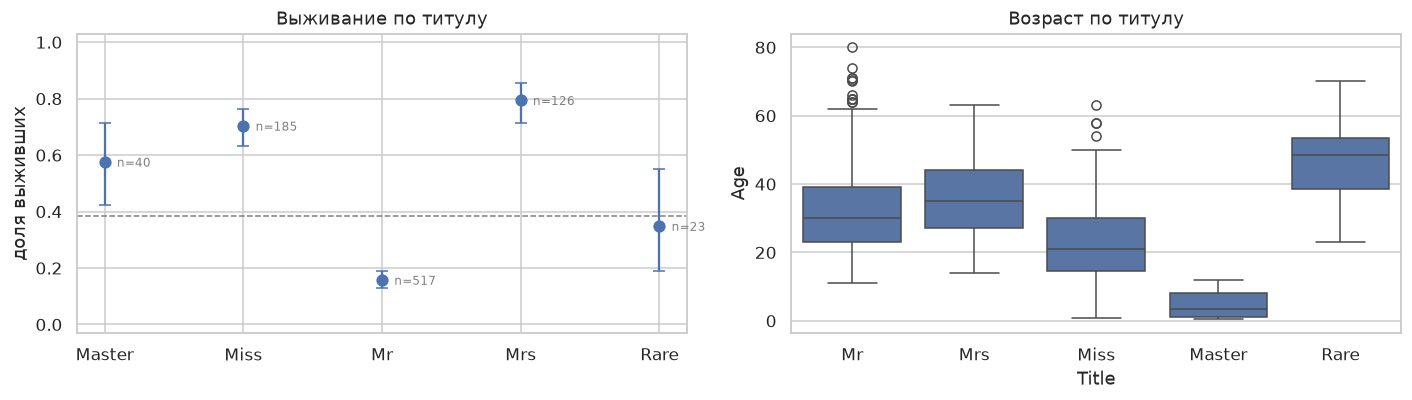

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_rates(rate_table(train_f, "Title"), "Title", axes[0], "Выживание по титулу")
sns.boxplot(train_f.to_pandas(), x="Title", y="Age", ax=axes[1])
axes[1].set_title("Возраст по титулу")
plt.tight_layout()
plt.show()

**Что видим:**
- **Master** — это мальчики (медиана возраста 3.5 года). Выживают на 57% при 16% у Mr. Титул ловит
  «ребёнок мужского пола» **даже когда возраст пропущен**.
- Miss моложе Mrs (21 против 35) — у Miss без возраста лучше заполнять медианой Miss.
- Редкие титулы (Rev, Dr, Col...) — смесь, по отдельности статистически ни о чём (по 1-7 человек).
  Сводим в `Rare`, иначе модель запомнит конкретных людей.
- В test есть титул `Dona`, которого нет в train. **В проде всегда будут невиданные категории** —
  их нужно явно маппить, а не падать.

## 7. Семья: U-образная зависимость

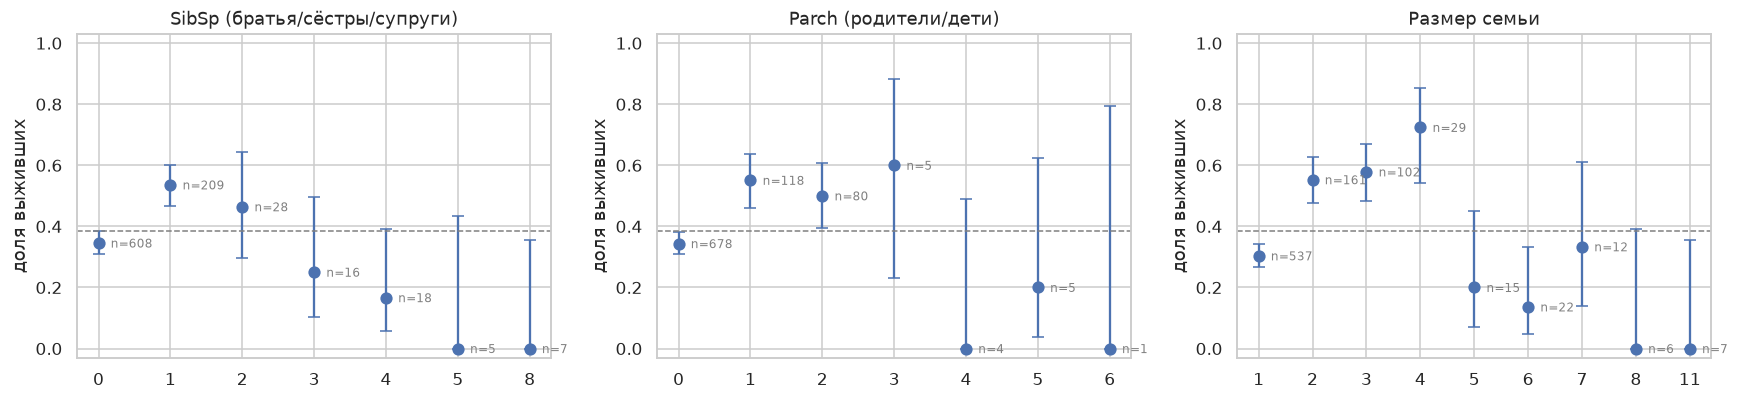

In [15]:
full = full.with_columns((pl.col("SibSp") + pl.col("Parch") + 1).alias("FamilySize"))
train_f = full.filter(pl.col("split") == "train")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
plot_rates(rate_table(train_f, "SibSp"), "SibSp", axes[0], "SibSp (братья/сёстры/супруги)")
plot_rates(rate_table(train_f, "Parch"), "Parch", axes[1], "Parch (родители/дети)")
plot_rates(rate_table(train_f, "FamilySize"), "FamilySize", axes[2], "Размер семьи")
plt.tight_layout()
plt.show()

**Что видим:** одиночки выживают на 30%, семьи из 2-4 — на 55-72%, большие семьи (5+) — почти никто.
Зависимость **немонотонная**: линейная модель на сыром `FamilySize` её не поймает (ей нужна корзина или
квадрат), а дерево — поймает сразу. Это первый аргумент в споре «логрег vs деревья» на следующем ноутбуке.

Почему так? Одиночки — в основном мужчины 3-го класса. Большие семьи — почти все 3-й класс, и им было
тяжело собраться вместе и дойти до шлюпок. Опять состав группы, а не сам размер семьи.

## 8. Билет: группы, которые путешествовали вместе

Одинаковый номер билета = одна покупка = люди путешествовали вместе (семья, друзья, слуги с хозяевами).
Это более точная «группа», чем SibSp/Parch: туда попадают и не родственники.

In [16]:
full = full.with_columns(pl.len().over("Ticket").alias("TicketGroupSize"))
train_f = full.filter(pl.col("split") == "train")
sizes = full["TicketGroupSize"].value_counts().sort("TicketGroupSize")
print("размер группы по билету → сколько пассажиров в таких группах:")
print(dict(zip(sizes["TicketGroupSize"], sizes["count"])))
n_shared = full.filter((pl.col("split") == "test") & pl.col("Ticket").is_in(train["Ticket"].implode())).height
print(f"\nпассажиров test, у которых есть попутчик из train: {n_shared} из {test.height}")

размер группы по билету → сколько пассажиров в таких группах:
{1: 713, 2: 264, 3: 147, 4: 64, 5: 35, 6: 24, 7: 35, 8: 16, 11: 11}

пассажиров test, у которых есть попутчик из train: 152 из 418


**Выживали ли группы вместе?** Возьмём группы из ≥2 человек в train и проверим: если один выжил,
выше ли шанс у остальных? Чтобы не подглядывать в собственный ответ, для каждого считаем выживание **остальных**
членов группы (leave-one-out).

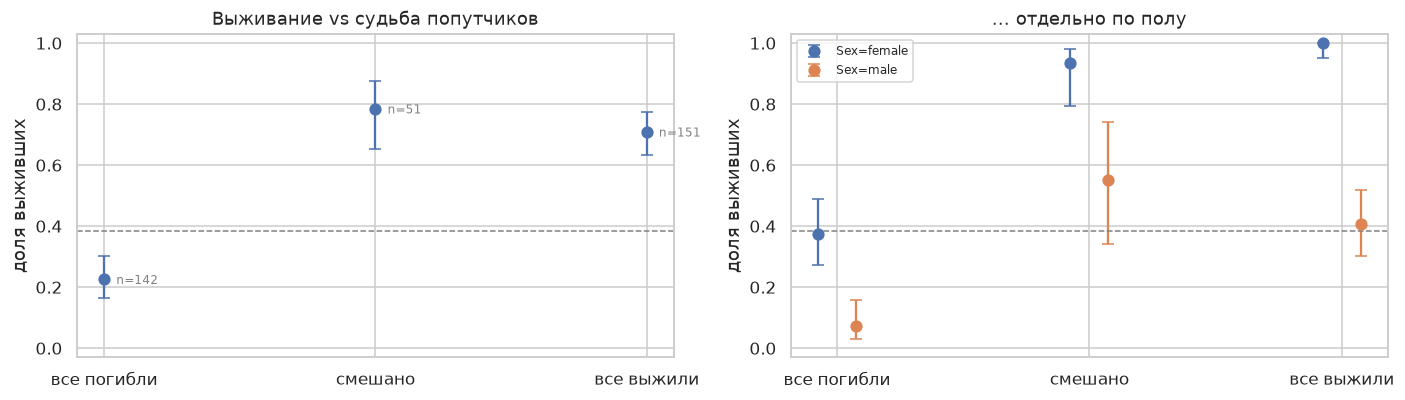

In [17]:
g = (train_f.filter(pl.col("TicketGroupSize") > 1)
     .with_columns(pl.len().over("Ticket").alias("n_in_train"), pl.col("Survived").sum().over("Ticket").alias("s_in_train"))
     .filter(pl.col("n_in_train") > 1)
     .with_columns(((pl.col("s_in_train") - pl.col("Survived")) / (pl.col("n_in_train") - 1)).alias("others_rate")))
g = g.with_columns(pl.col("others_rate").cut([0.001, 0.999], labels=["все погибли", "смешано", "все выжили"]).alias("others"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_rates(rate_table(g, "others"), "others", axes[0], "Выживание vs судьба попутчиков")
plot_rates(rate_table(g, ["others", "Sex"]), "others", axes[1], "... отдельно по полу", hue="Sex")
plt.tight_layout()
plt.show()

**Это самый сильный сигнал после пола.** И он работает **внутри пола**:

| | попутчики все погибли | смешано | попутчики все выжили |
|---|---|---|---|
| женщины | **38%** (n=72) | 94% (n=31) | 100% (n=77) |
| мужчины | 7% (n=70) | 55% (n=20) | **41%** (n=74) |

Женщина, чьи попутчики погибли, выживает в 2 раза реже средней женщины (74%). Мужчина, чьи попутчики выжили, —
в 2 раза чаще среднего мужчины (19%). Ровно там, где пол ошибается, группа его поправляет.

Особенно это важно для **женщин 3-го класса** (наша зона 50/50): часто вся семья погибала вместе
(большие семьи 3-го класса), и пол тут уже не спасал.

**Внимание, ловушка:** признак «судьба попутчиков» строится из таргета. Если посчитать его наивно (включая самого
человека) — это прямая утечка, на CV получим фантастические числа. На CV его надо считать **внутри фолда**:
только по попутчикам из обучающей части. В проде он выглядит так: «у этого пассажира попутчики в архиве с известным исходом».
Это **трансдуктивный** признак — он использует связи между объектами, а не только сам объект.

## 9. Тариф и каюта

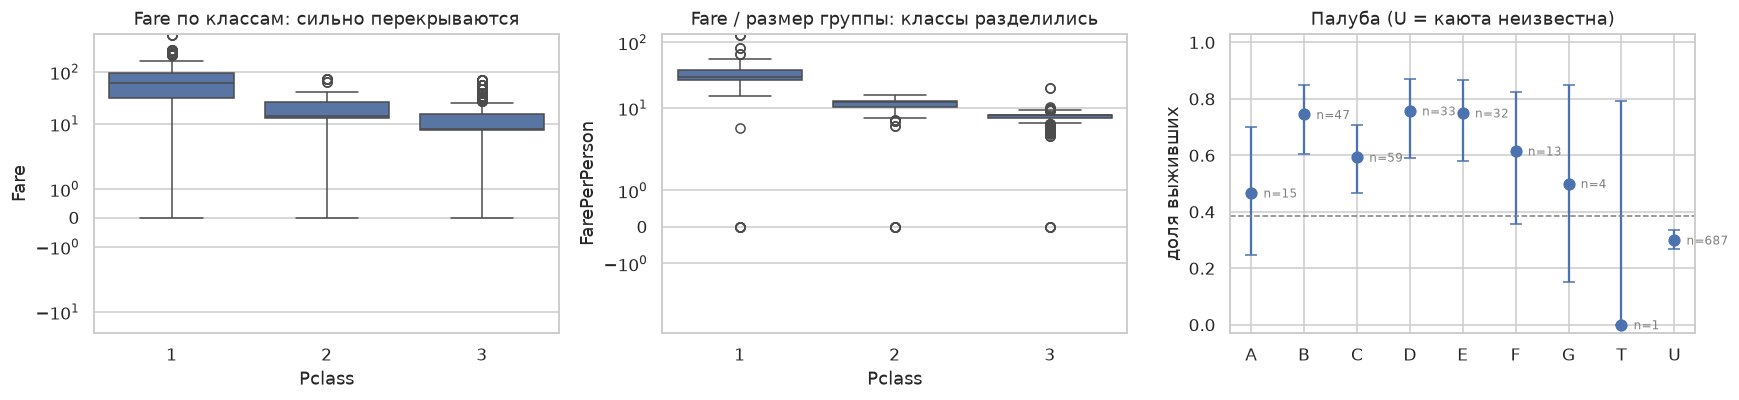

In [18]:
full = full.with_columns(
    (pl.col("Fare") / pl.col("TicketGroupSize")).alias("FarePerPerson"),
    pl.col("Cabin").str.slice(0, 1).fill_null("U").alias("Deck"),
)
train_f = full.filter(pl.col("split") == "train")
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
sns.boxplot(train_f.to_pandas(), x="Pclass", y="Fare", ax=axes[0])
axes[0].set_yscale("symlog")
axes[0].set_title("Fare по классам: сильно перекрываются")
sns.boxplot(train_f.to_pandas(), x="Pclass", y="FarePerPerson", ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_title("Fare / размер группы: классы разделились")
plot_rates(rate_table(train_f, "Deck"), "Deck", axes[2], "Палуба (U = каюта неизвестна)")
plt.tight_layout()
plt.show()

**Что видим:**
- `Fare` — цена **билета**, а не человека. Билет на семью из 7 человек 3-го класса стоит как билет 1-го класса.
  Поделив на размер группы, получаем `FarePerPerson` — и классы разделяются почти идеально. Это пример
  **понимания, что значит колонка**, а не просто подстановки её в модель.
- Палуба: у кого каюта известна, выживание ~67%; неизвестна — ~30%. Но неизвестная каюта — это в основном
  2-3 класс. Снова состав, не палуба. Буквы палуб A-G по отдельности малы и шумны — лучше брать флаг
  `HasCabin`, а не палубу.

## 10. Сводка: какие признаки сколько знают о таргете

Сравним признаки одной мерой — **взаимной информацией** $I(X;Y)$: сколько бит неопределённости о выживании
снимает знание признака. В отличие от корреляции, ловит и нелинейные зависимости (вроде U-образной семьи).

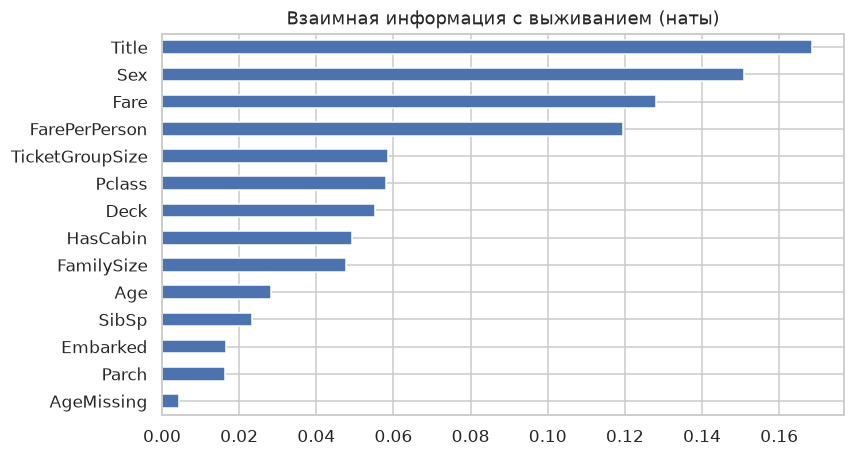

In [19]:
from sklearn.feature_selection import mutual_info_classif

feat = train_f.with_columns(
    pl.col("Cabin").is_not_null().cast(pl.Int8).alias("HasCabin"),
    pl.col("Age").is_null().cast(pl.Int8).alias("AgeMissing"),
).select("Sex", "Title", "Pclass", "Embarked", "Deck", "HasCabin", "AgeMissing",
         "SibSp", "Parch", "FamilySize", "TicketGroupSize", "Age", "Fare", "FarePerPerson").to_pandas()
discrete = [not pd.api.types.is_float_dtype(feat[c]) for c in feat.columns]
X = feat.copy()
for c in X.columns:
    if not pd.api.types.is_numeric_dtype(X[c]):
        X[c] = X[c].fillna("NA").astype("category").cat.codes
X = X.fillna(X.median(numeric_only=True))
mi = pd.Series(mutual_info_classif(X, train_f["Survived"].to_numpy(), discrete_features=discrete, random_state=0),
               index=X.columns).sort_values()
ax = mi.plot.barh(figsize=(8, 4.5), title="Взаимная информация с выживанием (наты)")
plt.show()

- **Титул и пол** впереди, и титул сильнее пола: он знает ещё и про детей (Master).
- **Тариф выше класса.** Fare — это «класс в высоком разрешении»: внутри класса цены сильно различаются
  (каюта получше, ближе к шлюпочной палубе), плюс в цене билета спрятан размер группы. Три уровня `Pclass`
  теряют эту информацию. Оговорка: для непрерывных признаков sklearn оценивает MI по ближайшим соседям,
  для дискретных — по частотам, так что сравнение между ними примерное.
- `AgeMissing` почти ноль: пропуск возраста статистически значим (p ≈ 0.006), но эффект маленький. Значимость ≠ сила.

Сырые SibSp/Parch/Age сами по себе слабые — их сила во взаимодействиях
(ребёнок мужского пола, большая семья 3-го класса), которые одномерная мера не видит.

Признака «судьба попутчиков» здесь нет — его нельзя честно посчитать без схемы фолдов. Сделаем это в `02_models`.

## Мысли

1. **Задача почти решена правилом.** Пол даёт 0.787. Всё, что выше, — это борьба за ~100 человек: женщин 3-го класса
   (50/50) и мужчин 1-го класса (37%). Хорошая модель — это не «больше признаков», а **правильные признаки для этих двух групп**.
2. **Связи между объектами сильнее свойств объекта.** Судьба попутчиков по билету — самый сильный сигнал после пола.
   Это идея, которая выходит далеко за Titanic: в антифроде (общие устройства и карты), в кредитах (созаёмщики),
   в рекомендациях (что купили похожие) граф связей часто важнее анкеты.
3. **Сырые доли обманывают.** Порт C «спасал» только потому, что там садился 1-й класс. Палуба — то же самое.
   Прежде чем делать вывод «X влияет на Y», спроси: чем отличаются группы по составу?
4. **Пропуски несут смысл.** Возраст пропущен чаще у тех, кто погиб и был в 3-м классе. Флаг пропуска — признак.
5. **Понимай колонку, прежде чем кормить модель.** Fare — цена билета на группу, а не на человека.
   Одно деление — и признак стал чистым.
6. **Маленькие данные = широкие интервалы.** 891 человек; стандартная ошибка accuracy ≈ 1.6 п.п. Разница
   0.78 vs 0.79 на LB (418 человек, ошибка ≈ 2 п.п.) — скорее всего шум. Это определит, как мы будем
   сравнивать модели: повторная CV, а не одна цифра.

**В модель берём:** Sex, Title, Pclass, AgeFilled (по титулу и классу) + AgeMissing, FamilySize (корзинами),
TicketGroupSize, FarePerPerson, HasCabin, Embarked, и — главное — групповой признак «судьба попутчиков» внутри фолда.